# Дерево решений: правила, сложность и обрезка

Дерево решений превращает таблицу заказов в последовательность проверок: например, достаточно ли загружен склад и сколько дней обещано на доставку. В этой практике мы увидим, как возникает правило, почему доля задержек в листе становится вероятностью и как ограничить слишком подробное дерево. Цель остаётся прежней: оценить риск задержки при оформлении заказа, когда фактическое время доставки ещё неизвестно.

Мы используем только двенадцать признаков, известных в момент заказа. Обучение идёт на ранних заказах 2026 года, проверка — на более позднем интервале. Между ними оставлена пауза для появления меток. Финальный тест отложен до завершающего занятия модуля: здесь его оценки и выбор настроек по нему отсутствуют. Все результаты ниже вычислены в сохранённом ноутбуке.

## Данные и правила временной проверки

Сначала закрепим контракт признаков и временные границы. Каждая строка — заказ, а `late_delivery` сообщает о задержке спустя семь дней. Поля о фактической задержке и компенсации возникают после оформления, поэтому в модель не попадают. Пропуски будут заполняться внутри `Pipeline` по обучающей части; незнакомая категория сможет пройти через кодирование без ошибки.

Проверочная выборка отражает следующие по времени заказы. Временная пауза защищает от ситуации, когда для обучающего заказа метка ещё не стала доступной к началу проверки. Для краткости далее обозначим эти части `train` и `validation`.

**Импорты и чтение заказов**

Все библиотеки этого автономного ноутбука собраны в первой кодовой ячейке. Данные читаются относительно каталога занятия. Сразу переводим даты в `datetime` и сортируем строки по времени, чтобы последующие проверки и кросс-валидация работали с реальным порядком поступления заказов.

In [1]:
# Шаг М2.03.01 — Импорты и чтение заказов
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score, precision_score, recall_score, confusion_matrix

NUMERIC = ['distance_km', 'items_count', 'order_amount', 'warehouse_load', 'customer_prior_orders', 'promised_days', 'order_hour']
CATEGORICAL = ['city', 'product_category', 'delivery_type', 'weather_forecast', 'is_weekend']
FEATURES = NUMERIC + CATEGORICAL
data = pd.read_csv(Path('data/delivery_risk.csv'), parse_dates=['order_ts', 'label_available_at'])
data = data.sort_values('order_ts').reset_index(drop=True)
print('Заказов:', len(data), 'Признаков:', len(FEATURES))
print('Период:', data.order_ts.min(), '—', data.order_ts.max())

Заказов: 14000 Признаков: 12
Период: 2026-01-01 00:00:00 — 2026-12-31 23:59:00


**Аудит допустимых полей**

Проверим, что двенадцать признаков существуют и что служебные идентификаторы и сведения о результате доставки в них не затесались. Это защищает дальнейшие сравнения моделей от незаметной утечки при расширении CSV.

In [2]:
# Шаг М2.03.02 — Аудит допустимых полей
forbidden = {'request_id', 'customer_id', 'order_ts', 'label_available_at', 'actual_delay_hours', 'compensation_paid', 'late_delivery'}
assert len(FEATURES) == 12 and len(set(FEATURES)) == 12
assert set(FEATURES).isdisjoint(forbidden)
assert set(FEATURES).issubset(data.columns)
print('Допустимые признаки:', FEATURES)
print('Доля задержек:', round(data.late_delivery.mean(), 3))

Допустимые признаки: ['distance_km', 'items_count', 'order_amount', 'warehouse_load', 'customer_prior_orders', 'promised_days', 'order_hour', 'city', 'product_category', 'delivery_type', 'weather_forecast', 'is_weekend']
Доля задержек: 0.126


**Разделение по времени и зрелость меток**

Используем установленные границы: обучение до 25 июля, проверка с 1 августа до 24 сентября. Семидневные зазоры перед проверкой и итоговым тестом оставляют ответам время появиться. Здесь тестовые строки вообще не выбираются в рабочие переменные.

In [3]:
# Шаг М2.03.03 — Разделение по времени и зрелость меток
train = data.loc[data.order_ts < '2026-07-25'].copy()
validation = data.loc[(data.order_ts >= '2026-08-01') & (data.order_ts < '2026-09-24')].copy()
assert train.label_available_at.max() < validation.order_ts.min()
X_train, y_train = train[FEATURES], train.late_delivery
X_val, y_val = validation[FEATURES], validation.late_delivery
print(pd.DataFrame({'строк': [len(train), len(validation)], 'доля задержек': [y_train.mean(), y_val.mean()]}, index=['обучение', 'проверка']).round(3))
print('Последняя доступная обучающая метка:', train.label_available_at.max())
print('Первый проверочный заказ:', validation.order_ts.min())

          строк  доля задержек
обучение   7863          0.118
проверка   2072          0.115
Последняя доступная обучающая метка: 2026-07-31 23:42:27
Первый проверочный заказ: 2026-08-01 00:02:11


**Подготовка внутри модели**

Числа заполняются медианой, а индикаторы пропуска сохраняют информацию о том, что исходное значение отсутствовало. Категории заполняются частым значением и кодируются с обработкой незнакомых значений. Дереву не нужно масштабирование чисел: оно сравнивает признаки с порогом, и порядок значений от изменения масштаба не меняется.

In [4]:
# Шаг М2.03.04 — Подготовка внутри модели
def make_tree(**kwargs):
    prepare = ColumnTransformer([
        ('numeric', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True))]), NUMERIC),
        ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                                  ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CATEGORICAL),
    ])
    return Pipeline([('prepare', prepare), ('model', DecisionTreeClassifier(random_state=42, **kwargs))])

probe = make_tree(max_depth=2).fit(X_train, y_train)
print('Размер матрицы после подготовки:', probe.named_steps['prepare'].transform(X_train).shape)
print('Настройки первого дерева:', probe.named_steps['model'].get_params()['max_depth'])

Размер матрицы после подготовки: (7863, 43)
Настройки первого дерева: 2


Мы получили воспроизводимую пару `train`/`validation` и единый шаблон `Pipeline`. Теперь можно разбирать именно дерево: что оно оптимизирует и почему небольшой локальный выигрыш способен привести к слишком сложной модели.

## Как дерево выбирает вопросы

Внутренний узел задаёт условие по одному признаку и порогу. Заказ уходит в левую или правую ветвь, пока не попадёт в лист. В листе хранится частота классов среди обучающих заказов, дошедших туда. Для выбора условия алгоритм обычно перебирает возможные разбиения и берёт то, которое сильнее уменьшает смешанность классов; это жадное решение без поиска лучшего целого дерева.

На маленьком числовом примере посчитаем индекс Джини, энтропию и взвешенную смешанность после разбиения. Затем посмотрим на реальное небольшое дерево и его вероятности.

**Индекс Джини на шести заказах**

Возьмём ровно три задержанных и три своевременных заказа. Индекс Джини равен `1 − сумма квадратов долей классов`; чистый узел даёт ноль, смешанный — положительное значение.

In [5]:
# Шаг М2.03.05 — Индекс Джини на шести заказах
small_y = np.array([0, 0, 0, 1, 1, 1])
def gini(values):
    shares = np.bincount(values, minlength=2) / len(values)
    return 1 - np.sum(shares ** 2)
print('Доли классов:', np.bincount(small_y) / len(small_y))
print('Джини исходного узла:', gini(small_y))

Доли классов: [0.5 0.5]
Джини исходного узла: 0.5


**Энтропия того же узла**

Энтропия использует `−сумма p·log₂(p)` по ненулевым долям. Для равных классов она равна одному биту. Это альтернативная мера смешанности, а не новая метрика качества прогноза.

In [6]:
# Шаг М2.03.06 — Энтропия того же узла
def entropy(values):
    shares = np.bincount(values, minlength=2) / len(values)
    shares = shares[shares > 0]
    return -np.sum(shares * np.log2(shares))
print('Энтропия смешанного узла:', entropy(small_y))
print('Энтропия чистого узла:', entropy(np.zeros(6, dtype=int)))

Энтропия смешанного узла: 1.0
Энтропия чистого узла: -0.0


**Взвешенная смешанность разбиения**

Пусть вопрос разделил шесть заказов на группы по два и четыре: слева оба вовремя, справа один вовремя и три задержаны. Вклад каждой дочерней группы умножается на её долю строк. Сравним смешанность до и после такого вопроса.

In [7]:
# Шаг М2.03.07 — Взвешенная смешанность разбиения
left_y, right_y = np.array([0, 0]), np.array([0, 1, 1, 1])
weighted_gini = len(left_y)/len(small_y)*gini(left_y) + len(right_y)/len(small_y)*gini(right_y)
weighted_entropy = len(left_y)/len(small_y)*entropy(left_y) + len(right_y)/len(small_y)*entropy(right_y)
print('Джини до / после / выигрыш:', round(gini(small_y), 3), round(weighted_gini, 3), round(gini(small_y)-weighted_gini, 3))
print('Энтропия до / после / выигрыш:', round(entropy(small_y), 3), round(weighted_entropy, 3), round(entropy(small_y)-weighted_entropy, 3))

Джини до / после / выигрыш: 0.5 0.25 0.25
Энтропия до / после / выигрыш: 1.0 0.541 0.459


**Лист и его вероятность**

Ограничим дерево одним уровнем. Для нескольких проверочных заказов посмотрим, в какой лист они попадают, сколько обучающих строк лежит в этих листьях и какую долю задержек модель возвращает как `predict_proba`. Это частота в обучающем листе, а не гарантия калибровки на будущем.

In [8]:
# Шаг М2.03.08 — Лист и его вероятность
stump = make_tree(max_depth=1, min_samples_leaf=50).fit(X_train, y_train)
prepared_val = stump.named_steps['prepare'].transform(X_val.iloc[:8])
leaf_ids = stump.named_steps['model'].apply(prepared_val)
tree_obj = stump.named_steps['model'].tree_
print(pd.DataFrame({'лист': leaf_ids, 'заказов_в_обучающем_листе': tree_obj.n_node_samples[leaf_ids],
                    'вероятность_задержки': stump.predict_proba(X_val.iloc[:8])[:, 1]}).round(3).to_string(index=False))

 лист  заказов_в_обучающем_листе  вероятность_задержки
    2                       1569                 0.243
    1                       6294                 0.087
    1                       6294                 0.087
    1                       6294                 0.087
    2                       1569                 0.243
    2                       1569                 0.243
    2                       1569                 0.243
    1                       6294                 0.087


**Показываем короткое дерево**

Нарисуем первые два уровня модели с ограниченной глубиной. На схеме указаны условие, смешанность, число обучающих примеров и состав классов. После кодирования категорий один исходный категориальный признак превращается в несколько проверок индикаторов.

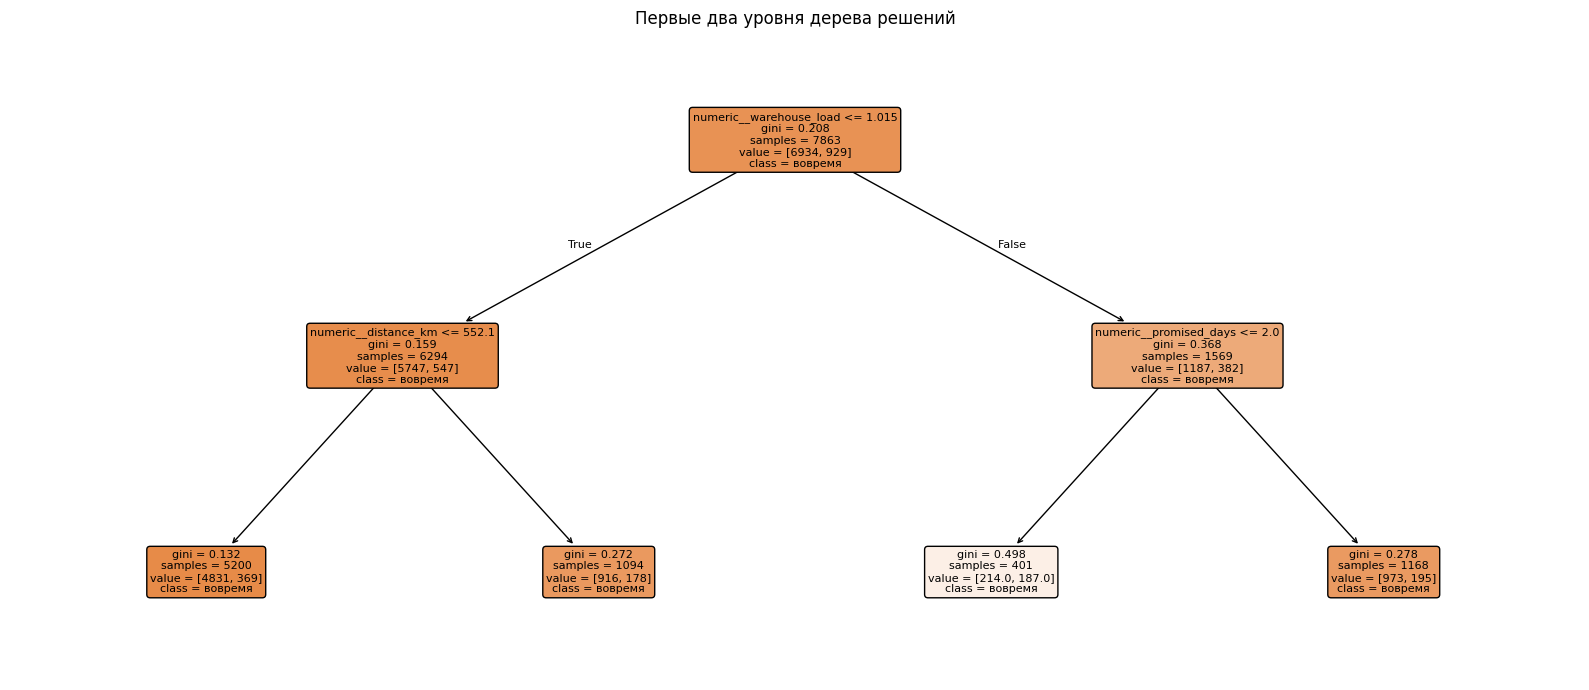

In [9]:
# Шаг М2.03.09 — Показываем короткое дерево
short_tree = make_tree(max_depth=2, min_samples_leaf=100).fit(X_train, y_train)
names = short_tree.named_steps['prepare'].get_feature_names_out()
plt.figure(figsize=(16, 7))
plot_tree(short_tree.named_steps['model'], feature_names=names, class_names=['вовремя', 'задержка'],
          filled=True, rounded=True, fontsize=8, impurity=True)
plt.title('Первые два уровня дерева решений')
plt.tight_layout()
plt.show()

Локальный выигрыш по Джини или энтропии объясняет, как дерево строится, а частоты листьев объясняют его `predict_proba`. Следующий вопрос — насколько глубоко можно продолжать делить заказы, прежде чем правила начнут отражать случайные детали обучения.

## Сложность и переобучение

Без ограничений дерево продолжает разбиения до очень малых листьев. Оно может почти идеально запомнить обучение, но качество на поздних заказах ухудшится. Глубина ограничивает число последовательных вопросов, а `min_samples_leaf` запрещает листья с числом обучающих примеров меньше порога. Эти параметры регулируют разные стороны одной проблемы.

Оценим качество на обучении и проверке, затем построим кривые для глубины и минимального размера листа. В качестве основной метрики ранжирования здесь используем AP, уже введённую ранее в модуле.

**Дерево без ограничения глубины**

Обучим стандартное дерево и сравним число узлов, фактическую глубину, AP на обучении и проверке. Резкое расхождение — признак подгонки под особенности раннего периода.

In [10]:
# Шаг М2.03.10 — Дерево без ограничения глубины
unrestricted = make_tree().fit(X_train, y_train)
u_model = unrestricted.named_steps['model']
print('Глубина:', u_model.get_depth(), 'узлов:', u_model.tree_.node_count, 'листьев:', u_model.get_n_leaves())
print('AP обучение:', round(average_precision_score(y_train, unrestricted.predict_proba(X_train)[:, 1]), 3))
print('AP проверка:', round(average_precision_score(y_val, unrestricted.predict_proba(X_val)[:, 1]), 3))

Глубина: 25 узлов: 1997 листьев: 999
AP обучение: 1.0
AP проверка: 0.133


**Таблица качества для разных глубин**

Изменим только `max_depth`, сохраняя остальные настройки. Для каждой глубины посчитаем AP и F1 на обоих периодах. Проверочные значения используются для учебного анализа и выбора кандидата, не для многократной подгонки под итоговый тест.

In [11]:
# Шаг М2.03.11 — Таблица качества для разных глубин
depth_rows = []
for depth in [2, 3, 4, 5, 7, 9, 12, None]:
    pipe = make_tree(max_depth=depth).fit(X_train, y_train)
    for part, X_part, y_part in [('обучение', X_train, y_train), ('проверка', X_val, y_val)]:
        depth_rows.append({'глубина': str(depth), 'часть': part,
                           'AP': average_precision_score(y_part, pipe.predict_proba(X_part)[:, 1]),
                           'F1': f1_score(y_part, pipe.predict(X_part)),
                           'листьев': pipe.named_steps['model'].get_n_leaves()})
depth_results = pd.DataFrame(depth_rows)
print(depth_results.round(3).to_string(index=False))

глубина    часть    AP    F1  листьев
      2 обучение 0.232 0.000        4
      2 проверка 0.218 0.000        4
      3 обучение 0.289 0.115        8
      3 проверка 0.263 0.101        8
      4 обучение 0.337 0.245       16
      4 проверка 0.277 0.233       16
      5 обучение 0.381 0.264       32
      5 проверка 0.259 0.163       32
      7 обучение 0.492 0.390      106
      7 проверка 0.199 0.180      106
      9 обучение 0.622 0.519      227
      9 проверка 0.190 0.194      227
     12 обучение 0.811 0.727      487
     12 проверка 0.147 0.144      487
   None обучение 1.000 1.000      999
   None проверка 0.133 0.209      999


**Вывод по глубине.** В сохранённом результате обучение становится всё легче для дерева: на максимальной свободной глубине AP достигает 1,000. На validation она опускается примерно до 0,131, тогда как дерево глубины пять получает около 0,259 в этом опыте без ограничения листа. Такой разрыв показывает запоминание конкретных заказов. Следует сравнивать не только абсолютную AP, но и устойчивость между периодами; увеличение сложности после некоторого предела уже не переносит пользу на будущие строки.

**Кривая глубины**

Покажем разрыв между периодами на одном графике. Визуальное сравнение помогает найти область умеренной сложности, где проверочное качество перестаёт выигрывать от новых ветвей.

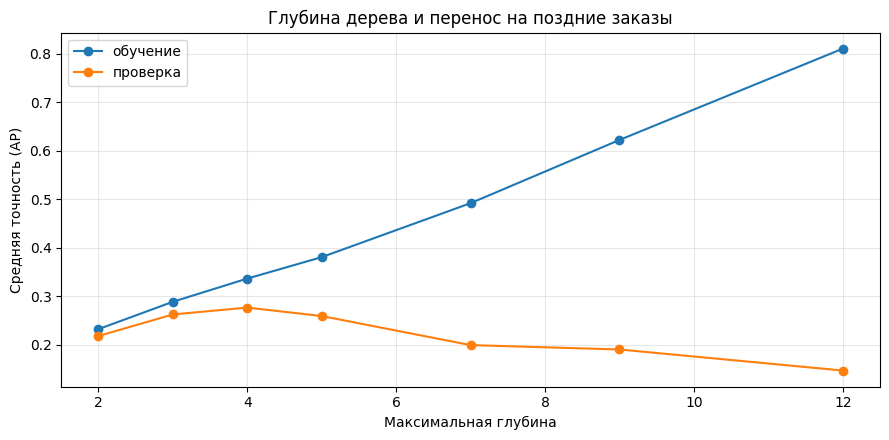

In [12]:
# Шаг М2.03.12 — Кривая глубины
plot_depth = depth_results.loc[depth_results['глубина'] != 'None'].copy()
fig, ax = plt.subplots(figsize=(9, 4.5))
for part in ['обучение', 'проверка']:
    z = plot_depth.loc[plot_depth['часть'] == part]
    ax.plot(z['глубина'].astype(int), z['AP'], marker='o', label=part)
ax.set(xlabel='Максимальная глубина', ylabel='Средняя точность (AP)', title='Глубина дерева и перенос на поздние заказы')
ax.grid(alpha=.3); ax.legend(); plt.tight_layout(); plt.show()

**Ограничение размера листа**

При фиксированной глубине пять сравним несколько размеров листа. Больший лист сглаживает долю задержек и сокращает число мелких правил; слишком большой лист может потерять полезные различия между заказами.

In [13]:
# Шаг М2.03.13 — Ограничение размера листа
leaf_rows = []
for leaf in [1, 15, 50, 100, 250]:
    pipe = make_tree(max_depth=5, min_samples_leaf=leaf).fit(X_train, y_train)
    leaf_rows.append({'минимум_в_листе': leaf, 'листьев': pipe.named_steps['model'].get_n_leaves(),
                      'AP_обучение': average_precision_score(y_train, pipe.predict_proba(X_train)[:, 1]),
                      'AP_проверка': average_precision_score(y_val, pipe.predict_proba(X_val)[:, 1])})
leaf_results = pd.DataFrame(leaf_rows)
print(leaf_results.round(3).to_string(index=False))

 минимум_в_листе  листьев  AP_обучение  AP_проверка
               1       32        0.381        0.259
              15       31        0.379        0.273
              50       27        0.359        0.296
             100       23        0.333        0.282
             250       16        0.299        0.275


**Разброс вероятностей дерева**

Сравним число различных вероятностей и крайних значений у свободного и ограниченного дерева. В листовой модели вероятности ступенчатые: все заказы одного листа получают одно число.

In [14]:
# Шаг М2.03.14 — Разброс вероятностей дерева
limited = make_tree(max_depth=5, min_samples_leaf=50).fit(X_train, y_train)
for name, pipe in [('свободное', unrestricted), ('ограниченное', limited)]:
    p = pipe.predict_proba(X_val)[:, 1]
    print(name, 'различных вероятностей:', len(np.unique(p)),
          'доля нулевых или единичных:', round(np.mean((p == 0) | (p == 1)), 3),
          'AP:', round(average_precision_score(y_val, p), 3))

свободное различных вероятностей: 2 доля нулевых или единичных: 1.0 AP: 0.133
ограниченное различных вероятностей: 27 доля нулевых или единичных: 0.0 AP: 0.296


Дерево без ограничений подстраивается под обучение, а контроль глубины и размера листа улучшает устойчивость оценок. Подбор этих параметров следует перенести внутрь раннего периода, чтобы внешний validation остался отдельной проверкой выбранного решения.

## Временная кросс-валидация и подбор

Кросс-валидация повторяет обучение и проверку на нескольких частях данных. В данном случае обычная случайная стратификация разрушила бы порядок заказов и могла бы подмешать будущие случаи в обучение. `TimeSeriesSplit` строит возрастающее прошлое и следующий временной блок. Параметр `gap=300` оставляет между ними неиспользованные строки, превосходящие семидневное ожидание метки в этом наборе.

`GridSearchCV` обучит один и тот же `Pipeline` для небольшой сетки глубины и размера листа. Лучшие настройки определяются по средней AP внутренних временных проверок. Внешний validation остаётся отдельной оценкой результата выбора.

**Границы трёх внутренних сгибов**

Посмотрим не только на размеры, но и на реальные даты обучающих и проверочных блоков. В каждом сгибе индекс обучающего блока предшествует индексу проверочного.

In [15]:
# Шаг М2.03.15 — Границы трёх внутренних сгибов
cv = TimeSeriesSplit(n_splits=3, gap=300)
fold_rows = []
for number, (tr_idx, va_idx) in enumerate(cv.split(X_train), 1):
    fold_rows.append({'сгиб': number, 'обучение_строк': len(tr_idx), 'проверка_строк': len(va_idx),
                      'последний_заказ_обучения': train.iloc[tr_idx].order_ts.max(),
                      'первый_заказ_проверки': train.iloc[va_idx].order_ts.min()})
print(pd.DataFrame(fold_rows).to_string(index=False))

 сгиб  обучение_строк  проверка_строк последний_заказ_обучения первый_заказ_проверки
    1            1668            1965      2026-02-13 11:08:17   2026-02-21 07:29:28
    2            3633            1965      2026-04-05 16:45:08   2026-04-13 13:06:19
    3            5598            1965      2026-05-26 22:21:58   2026-06-03 18:43:10


**Проверка созревания меток внутри CV**

Для каждого сгиба явно убедимся, что последняя доступная метка обучающей части предшествует первому проверочному заказу. Это проверяет фактическое условие, а не только число пропущенных строк.

In [16]:
# Шаг М2.03.16 — Проверка созревания меток внутри CV
for number, (tr_idx, va_idx) in enumerate(cv.split(X_train), 1):
    last_label = train.iloc[tr_idx].label_available_at.max()
    first_order = train.iloc[va_idx].order_ts.min()
    assert last_label < first_order
    print(f'Сгиб {number}: метки доступны до {last_label}, проверка начинается {first_order}')

Сгиб 1: метки доступны до 2026-02-20 11:08:17, проверка начинается 2026-02-21 07:29:28
Сгиб 2: метки доступны до 2026-04-12 16:45:08, проверка начинается 2026-04-13 13:06:19
Сгиб 3: метки доступны до 2026-06-02 22:21:58, проверка начинается 2026-06-03 18:43:10


**Небольшая сетка GridSearchCV**

Переберём три глубины и три размера листа. Сетка достаточно мала для занятия и проверяет область, где модель не разрастается бесконтрольно. Целевая метрика — AP, поскольку задержки составляют меньшинство заказов.

In [17]:
# Шаг М2.03.17 — Небольшая сетка GridSearchCV
search = GridSearchCV(make_tree(), {'model__max_depth': [3, 5, 7], 'model__min_samples_leaf': [30, 50, 100]},
                      scoring='average_precision', cv=cv, n_jobs=1, refit=True)
search.fit(X_train, y_train)
print('Лучшие параметры:', search.best_params_)
print('Средняя AP внутренних проверок:', round(search.best_score_, 3))

Лучшие параметры: {'model__max_depth': 7, 'model__min_samples_leaf': 100}
Средняя AP внутренних проверок: 0.29


**Разброс результатов сетки**

Сравним среднюю AP и её изменчивость между сгибами. Небольшое превосходство одной комбинации при заметном разбросе не стоит трактовать как физический закон о правильной глубине дерева.

In [18]:
# Шаг М2.03.18 — Разброс результатов сетки
cv_table = pd.DataFrame(search.cv_results_)[['param_model__max_depth', 'param_model__min_samples_leaf', 'mean_test_score', 'std_test_score', 'rank_test_score']]
cv_table = cv_table.sort_values('rank_test_score').rename(columns={'mean_test_score': 'средняя_AP', 'std_test_score': 'разброс_AP'})
print(cv_table.round(3).to_string(index=False))

 param_model__max_depth  param_model__min_samples_leaf  средняя_AP  разброс_AP  rank_test_score
                      7                            100       0.290       0.032                1
                      5                             50       0.289       0.033                2
                      7                             50       0.288       0.033                3
                      5                            100       0.286       0.029                4
                      5                             30       0.286       0.026                5
                      7                             30       0.284       0.022                6
                      3                             50       0.270       0.027                7
                      3                            100       0.268       0.023                8
                      3                             30       0.262       0.021                9


**Внешняя проверка выбранной настройки**

Оценим уже переобученную лучшую модель на validation. Выведем AP, ROC-AUC, F1, precision и recall, а также размеры дерева. Эти метрики применяются в смысле, изученном ранее, без повторного определения.

In [19]:
# Шаг М2.03.19 — Внешняя проверка выбранной настройки
selected = search.best_estimator_
selected_p = selected.predict_proba(X_val)[:, 1]
selected_y = selected.predict(X_val)
print(pd.Series({'AP': average_precision_score(y_val, selected_p), 'ROC-AUC': roc_auc_score(y_val, selected_p),
                 'F1': f1_score(y_val, selected_y), 'precision': precision_score(y_val, selected_y, zero_division=0),
                 'recall': recall_score(y_val, selected_y, zero_division=0),
                 'листьев': selected.named_steps['model'].get_n_leaves()}).round(3).to_string())

AP            0.282
ROC-AUC       0.697
F1            0.166
precision     0.605
recall        0.096
листьев      42.000


**Фиксированный кандидат для общего сравнения**

Сохраним заранее оговорённую конфигурацию `max_depth=5`, `min_samples_leaf=50`. Она воспроизводима независимо от небольших колебаний выбора сетки и станет кандидатом в итоговом сравнении моделей. Здесь считаем только её validation-качество.

In [20]:
# Шаг М2.03.20 — Фиксированный кандидат для общего сравнения
tree_candidate = make_tree(max_depth=5, min_samples_leaf=50).fit(X_train, y_train)
candidate_p = tree_candidate.predict_proba(X_val)[:, 1]
print('Дерево-кандидат, AP на validation:', round(average_precision_score(y_val, candidate_p), 3))
print('Глубина / листья:', tree_candidate.named_steps['model'].get_depth(), tree_candidate.named_steps['model'].get_n_leaves())

Дерево-кандидат, AP на validation: 0.296
Глубина / листья: 5 27


Временная CV дала несколько внутренних проверок и соблюла дату появления меток. Выбранная и фиксированная конфигурации оценены на внешнем validation; итоговый тест ещё не использован. Остался второй способ управлять сложностью дерева — обрезка уже выращенных ветвей.

## Обрезка дерева

`ccp_alpha` задаёт штраф за сложность дерева при cost-complexity pruning. При нуле дерево не обрезается по этому механизму; с ростом параметра некоторые ветви исчезают. Путь допустимых значений можно получить из обучающих данных. Мы рассмотрим несколько его точек и посмотрим, как меняются число листьев и качество на validation.

Проверочный интервал можно использовать для учебной оценки метода. Значение `ccp_alpha` не выбирается по итоговому тесту; поздняя тестовая часть здесь остаётся закрытой.

**Путь стоимости сложности на train**

Получим допустимые значения `ccp_alpha` после подготовки, обученной только на train. Для каждого значения существует поддерево, полученное последовательным удалением слабых ветвей.

In [21]:
# Шаг М2.03.21 — Путь стоимости сложности на train
prepared_train = tree_candidate.named_steps['prepare'].transform(X_train)
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(prepared_train, y_train)
alphas = np.unique(path.ccp_alphas)
print('Значений на пути:', len(alphas))
print('Диапазон alpha:', float(alphas.min()), '—', float(alphas.max()))

Значений на пути: 240
Диапазон alpha: 0.0 — 0.007829954881001938


**Число листьев вдоль пути**

Выберем несколько характерных штрафов, исключив крайний, который оставляет единственный лист. Посчитаем число листьев и AP на двух периодах для каждого значения.

In [22]:
# Шаг М2.03.22 — Число листьев вдоль пути
chosen_alphas = np.unique(np.quantile(alphas[:-1], [0, .25, .5, .75, .9, .98]))
prune_rows = []
for alpha in chosen_alphas:
    pipe = make_tree(ccp_alpha=float(alpha)).fit(X_train, y_train)
    prune_rows.append({'alpha': alpha, 'листьев': pipe.named_steps['model'].get_n_leaves(),
                       'AP_обучение': average_precision_score(y_train, pipe.predict_proba(X_train)[:, 1]),
                       'AP_проверка': average_precision_score(y_val, pipe.predict_proba(X_val)[:, 1])})
prune_results = pd.DataFrame(prune_rows)
print(prune_results.round(4).to_string(index=False))

 alpha  листьев  AP_обучение  AP_проверка
0.0000      999       1.0000       0.1333
0.0001      735       0.9398       0.1406
0.0002      398       0.7833       0.1403
0.0002      168       0.5987       0.1892
0.0003       43       0.4207       0.2366
0.0012        7       0.2791       0.2527


**График обрезки**

На графике совместим качество и число листьев. Значение alpha показываем на горизонтальной оси, чтобы визуально отделить упрощение структуры от изменений проверочной AP.

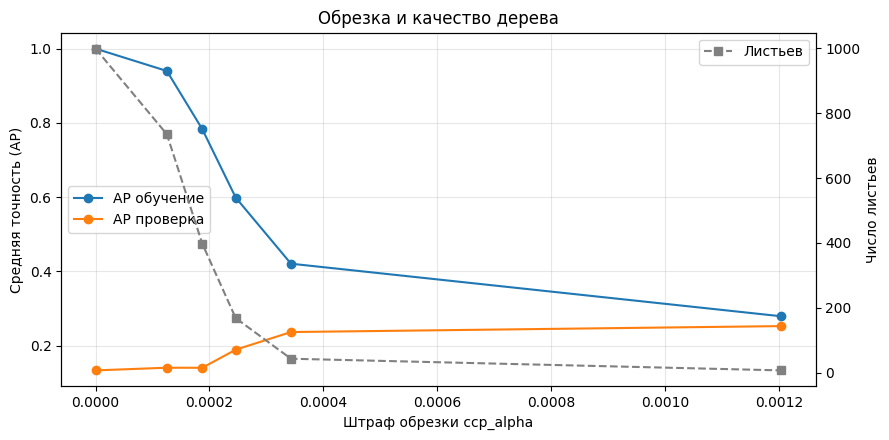

In [23]:
# Шаг М2.03.23 — График обрезки
fig, left_ax = plt.subplots(figsize=(9, 4.5))
left_ax.plot(prune_results.alpha, prune_results['AP_обучение'], marker='o', label='AP обучение')
left_ax.plot(prune_results.alpha, prune_results['AP_проверка'], marker='o', label='AP проверка')
left_ax.set(xlabel='Штраф обрезки ccp_alpha', ylabel='Средняя точность (AP)', title='Обрезка и качество дерева')
right_ax = left_ax.twinx()
right_ax.plot(prune_results.alpha, prune_results['листьев'], color='gray', linestyle='--', marker='s', label='Листьев')
right_ax.set_ylabel('Число листьев')
left_ax.grid(alpha=.3); left_ax.legend(loc='center left'); right_ax.legend(loc='upper right'); plt.tight_layout(); plt.show()

**Обрезанное дерево рядом с кандидатом**

Для сравнения возьмём середину рассмотренного пути, а не лучшую строку по validation. Сопоставим компактность и качество с фиксированным кандидатом, ограниченным глубиной и размером листа.

In [24]:
# Шаг М2.03.24 — Обрезанное дерево рядом с кандидатом
middle_alpha = float(chosen_alphas[len(chosen_alphas)//2])
pruned = make_tree(ccp_alpha=middle_alpha).fit(X_train, y_train)
comparison = pd.DataFrame([
    {'модель': 'фиксированное дерево', 'листьев': tree_candidate.named_steps['model'].get_n_leaves(), 'AP_проверка': average_precision_score(y_val, tree_candidate.predict_proba(X_val)[:, 1])},
    {'модель': 'обрезанное дерево', 'листьев': pruned.named_steps['model'].get_n_leaves(), 'AP_проверка': average_precision_score(y_val, pruned.predict_proba(X_val)[:, 1])}])
print(comparison.round(3).to_string(index=False))

              модель  листьев  AP_проверка
фиксированное дерево       27        0.296
   обрезанное дерево      168        0.189


Обрезка позволяет получить более компактное дерево за счёт штрафа `ccp_alpha`. Для общего сравнения курса оставляем фиксированного кандидата с глубиной пять и минимальным размером листа пятьдесят: его параметры не зависят от выбора alpha на позднем тесте.

## Важность признаков и итог дерева

`feature_importances_` суммирует уменьшения критерия смешанности, приписанные признакам во внутренних узлах. После one-hot кодирования одна исходная категория представлена несколькими столбцами; поэтому отдельно посмотрим на кодированные и агрегированные исходные признаки. Такая важность зависит от структуры дерева и обучающей выборки. Она не доказывает причинного влияния признака на доставку.

В конце зафиксируем прогнозы кандидата и матрицу ошибок на validation. Это завершает анализ дерева, сохраняя итоговый тест для последнего занятия.

**Важность кодированных столбцов**

Извлечём имена после подготовки и сопоставим их с `feature_importances_`. Сумма значений равна единице для дерева с разбиениями. Эта величина описывает уменьшение смешанности на train.

In [25]:
# Шаг М2.03.25 — Важность кодированных столбцов
encoded_names = tree_candidate.named_steps['prepare'].get_feature_names_out()
importance = pd.Series(tree_candidate.named_steps['model'].feature_importances_, index=encoded_names).sort_values(ascending=False)
print('Сумма важностей:', round(importance.sum(), 3))
print(importance.head(12).round(3).to_string())

Сумма важностей: 1.0
numeric__warehouse_load               0.352
numeric__distance_km                  0.232
numeric__promised_days                0.225
categorical__weather_forecast_Ясно    0.114
numeric__order_amount                 0.044
categorical__weather_forecast_Снег    0.014
categorical__is_weekend_Нет           0.009
numeric__order_hour                   0.005
categorical__delivery_type_Обычная    0.003
numeric__customer_prior_orders        0.002
numeric__items_count                  0.000
categorical__city_Волгоград           0.000


**Агрегация к исходным двенадцати признакам**

Сложим важности кодированных столбцов по исходным полям. Индикаторы пропуска числового признака тоже отнесём к его исходному полю. Результат удобнее для разговора о заказе, хотя ограничения метода сохраняются.

In [26]:
# Шаг М2.03.26 — Агрегация к исходным двенадцати признакам
raw_importance = {}
for raw in FEATURES:
    if raw in NUMERIC:
        mask = [name == f'numeric__{raw}' or name == f'numeric__missingindicator_{raw}' for name in importance.index]
    else:
        mask = [name.startswith(f'categorical__{raw}_') for name in importance.index]
    raw_importance[raw] = importance.loc[mask].sum()
raw_importance = pd.Series(raw_importance).sort_values(ascending=False)
print(raw_importance.round(3).to_string())
print('Сумма по исходным признакам:', round(raw_importance.sum(), 3))

warehouse_load           0.352
distance_km              0.232
promised_days            0.225
weather_forecast         0.129
order_amount             0.044
is_weekend               0.009
order_hour               0.005
delivery_type            0.003
customer_prior_orders    0.002
items_count              0.000
city                     0.000
product_category         0.000


Сумма по исходным признакам: 1.0


**Матрица ошибок кандидата**

Посмотрим, какие ошибки делает фиксированное дерево при стандартном пороге: отдельно пропущенные задержки и ложные предупреждения. В реальной задаче выбор порога зависел бы от стоимости этих двух ошибок.

In [27]:
# Шаг М2.03.27 — Матрица ошибок кандидата
candidate_pred = tree_candidate.predict(X_val)
matrix = confusion_matrix(y_val, candidate_pred)
print(pd.DataFrame(matrix, index=['факт: вовремя', 'факт: задержка'], columns=['прогноз: вовремя', 'прогноз: задержка']))
print('Precision:', round(precision_score(y_val, candidate_pred, zero_division=0), 3),
      'Recall:', round(recall_score(y_val, candidate_pred, zero_division=0), 3),
      'F1:', round(f1_score(y_val, candidate_pred), 3))

                прогноз: вовремя  прогноз: задержка
факт: вовремя               1808                 25
факт: задержка               212                 27
Precision: 0.519 Recall: 0.113 F1: 0.186


**Проверка воспроизводимого кандидата**

Зафиксируем параметры и основные validation-показатели одной строкой. Это итог дерева для дальнейшего сравнения, а не оценка на заключительном тестовом периоде.

In [28]:
# Шаг М2.03.28 — Проверка воспроизводимого кандидата
tree_summary = pd.Series({'модель': 'DecisionTreeClassifier', 'max_depth': 5, 'min_samples_leaf': 50,
                          'AP_validation': average_precision_score(y_val, candidate_p),
                          'ROC_AUC_validation': roc_auc_score(y_val, candidate_p),
                          'F1_validation': f1_score(y_val, candidate_pred),
                          'листьев': tree_candidate.named_steps['model'].get_n_leaves()})
print(tree_summary.to_string())

модель                DecisionTreeClassifier
max_depth                                  5
min_samples_leaf                          50
AP_validation                       0.296406
ROC_AUC_validation                  0.697146
F1_validation                       0.185567
листьев                                   27


Модель-кандидат, её настройки, качество и структура зафиксированы. Мы умеем читать дерево как набор правил, но понимаем пределы листовых вероятностей и важностей по уменьшению критерия. Окончательный тест остаётся нетронутым.

## Полученный результат

Мы рассчитали Джини и энтропию, проследили путь заказа до листа и увидели, как рост дерева увеличивает разрыв между обучением и проверкой. Внутренняя временная кросс-валидация с проверкой зрелости меток позволила подобрать настройки, а обрезка показала другой способ контроля сложности. Для общего сравнения оставлен воспроизводимый кандидат `DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, random_state=42)` в том же конвейере подготовки. Значения его метрик выше относятся только к validation.

Правила и важности дерева полезны для диагностики, но не дают причинных объяснений задержек. В следующем занятии оценим, что меняется, когда вместо одного дерева используется ансамбль. Финальный тест будет открыт только в заключительном сравнении моделей.

## Документация

[DecisionTreeClassifier в документации scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)

[Деревья решений в руководстве scikit-learn](https://scikit-learn.org/stable/modules/tree.html)

[TimeSeriesSplit в документации scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html)